# AI-generated PRs dataset (from the papers)
**Goal (Mohamed):** a dataset of **pull requests generated by AI agents** – how many per agent, the latest dates, Python – as the starting point for `linker.py`.

**Sources (all in `data/`):**
| Source | AI PRs | Note |
|---|---|---|
| AIDev-pop (in Alam's package) | 33,596 | all agents, Dec 2024 → Jul 2025, with **task type** (fix, feat…) |
| Who Finishes · Khemissi · Dovhoshliubnyi · Alam | – | their AI PRs are all inside AIDev-pop → we mark which paper uses each PR |
| Watanabe | 797 (756 new) | Claude Code PRs, Feb → Apr 2025 |
| **AIDev v4 (optional)** | 2,743,854 | on your PC (evolution-assurance/data/raw) – section 6 |

One row = **one AI-generated PR**. Extra column `fixed_later` = the papers found a later fix for it.

In [1]:
import sys, os, json, gzip, glob
sys.path.insert(0, "../..")
from common import *
D = os.path.join("..", "..", "..", "data")
OUT = os.path.join(D, "AI_PRS_DATASET"); os.makedirs(OUT, exist_ok=True)

## 1. AIDev-pop: the AI PRs, their repository language and task type

In [2]:
A = os.path.join(D, "08_Alam_AI_Fix_PRs", "Agents for Fixing", "dataset")
pr = pd.read_parquet(os.path.join(A, "pull_request.parquet"))
tt = pd.read_parquet(os.path.join(A, "pr_task_type.parquet"))[["id", "type"]]
rp = pd.read_parquet(os.path.join(A, "repository.parquet"))[["id", "full_name", "language", "stars"]].rename(columns={"id": "repo_id"})
pop = pr.merge(tt, on="id", how="left").merge(rp, on="repo_id", how="left")
ai = pd.DataFrame({"pr_id": pop["id"].astype(str), "pr_url": pop["html_url"], "agent": pop["agent"].map(agent_of), "repo": pop["full_name"],
    "language": pop["language"], "stars": pop["stars"], "title": pop["title"], "state": pop["state"],
    "created_at": pop["created_at"], "merged_at": pop["merged_at"], "closed_at": pop["closed_at"],
    "task_type": pop["type"], "source": "AIDev-pop"})
_ = overview(ai.drop(columns=["title"]), "AIDev-pop AI PRs")

**AIDev-pop AI PRs** — **33,596 rows × 12 columns** (8.6 MB in memory)

*First 5 lines:*

,pr_id,pr_url,agent,repo,language,stars,state,created_at,merged_at,closed_at,task_type,source
0,3264933329,https://github.com/milvus-io/pymilvus/pull/2911,Claude Code,milvus-io/pymilvus,Python,1230,closed,2025-07-26T02:59:01Z,NaN,2025-07-29T07:01:20Z,fix,AIDev-pop
1,3265118634,https://github.com/classmethod/tsumiki/pull/2,Claude Code,classmethod/tsumiki,TypeScript,391,closed,2025-07-26T04:56:55Z,2025-07-26T22:12:24Z,2025-07-26T22:12:24Z,refactor,AIDev-pop
2,3265640341,https://github.com/steipete/Peekaboo/pull/30,Claude Code,steipete/Peekaboo,Swift,505,closed,2025-07-26T13:31:19Z,2025-07-26T13:37:22Z,2025-07-26T13:37:22Z,feat,AIDev-pop
3,3265709660,https://github.com/sugyan/claude-code-webui/pull/205,Claude Code,sugyan/claude-code-webui,TypeScript,367,closed,2025-07-26T14:07:22Z,2025-07-26T14:45:30Z,2025-07-26T14:45:30Z,feat,AIDev-pop
4,3265782173,https://github.com/paradigmxyz/reth/pull/17625,Claude Code,paradigmxyz/reth,Rust,4835,open,2025-07-26T15:02:48Z,NaN,NaN,chore,AIDev-pop


*All columns:*

,column,type,missing_%,unique,example
0,pr_id,str,0.0,33596,3264933329
1,pr_url,str,0.0,33596,https://github.com/milvus-io/pymilvus/pull/2911
2,agent,str,0.0,5,Claude Code
3,repo,str,0.0,2807,milvus-io/pymilvus
4,language,str,0.5,85,Python
5,stars,int64,0.0,1640,1230
6,state,str,0.0,2,closed
7,created_at,str,0.0,33437,2025-07-26T02:59:01Z
8,merged_at,str,28.5,23978,2025-07-26T22:12:24Z
9,closed_at,str,6.9,30882,2025-07-29T07:01:20Z


## 2. Add the Claude Code PRs of Watanabe that are not in AIDev-pop

In [3]:
W = os.path.join(D, "04_Watanabe_ClaudeCode", "ontheuseofagenticcoding", "Data")
parts = []
for st, f in [("merged", "APR-MERGED.csv"), ("closed", "APR-CLOSED.csv"), ("open", "APR-OPEN.csv")]:
    t = pd.read_csv(os.path.join(W, f)); t["st"] = st; parts.append(t)
w = pd.concat(parts, ignore_index=True)
new = w[~w["url"].isin(ai["pr_url"])]
wa = pd.DataFrame({"pr_id": None, "pr_url": new["url"], "agent": "Claude Code", "repo": new["owner"] + "/" + new["repo_name"],
    "language": None, "stars": new["stars"], "title": None, "state": new["st"].map({"merged": "closed", "closed": "closed", "open": "open"}),
    "created_at": new["created_at"], "merged_at": new["merged_at"] if "merged_at" in new else None, "closed_at": None,
    "task_type": None, "source": "Watanabe 2025"})
print("Watanabe PRs:", len(w), "| already in AIDev-pop:", len(w) - len(new), "| added:", len(new))
ai = pd.concat([ai, wa], ignore_index=True)

Watanabe PRs: 797 | already in AIDev-pop: 41 | added: 756


## 3. Mark which papers use each PR, and whether it was fixed later

In [4]:
J = os.path.join(D, "01_WhoFinishes", "pr-fix-authorship", "data", "judge")
cases = load_json(os.path.join(J, "rq1_judge_cases_population_12k.json"))
v = pd.read_csv(os.path.join(J, "rq1_llm_judge_pop_anthropic_claude-opus-4-8_low.csv"))
wf_all = {c["p_url"] for c in cases}
wf_fix = set(v.loc[v.label == "Direct fix", "p_url"])
K = os.path.join(D, "09_Khemissi_References", "replication_package_v2", "results")
kh = pd.read_csv(os.path.join(K, "05_human_references_with_co_authors.csv"), low_memory=False, usecols=["target_pr_html_url", "source_commit_message"])
kh_all = set(kh.target_pr_html_url)
kh_fix = set(kh.loc[kh.source_commit_message.astype(str).str.contains(r"(?i)\b(fix(es|ed)?|bug|hotfix|revert(s|ed)?)\b"), "target_pr_html_url"])
dv = pd.read_csv(os.path.join(D, "06_Dovhoshliubnyi_Hunks", "ssbse-challenge-2026", "data", "msr_paper", "performance_prs_ai_vs_human.csv"), usecols=["html_url", "author_type"])
dv_all = set(dv.loc[dv.author_type == "AI Agent", "html_url"])
rev = pd.read_csv(os.path.join(W, "require_revision", "APR-require-revision.csv"))
wt_all, wt_fix = set(w.url), set(rev.url)
def papers(u):
    p = [n for n, s in [("Who Finishes", wf_all), ("Khemissi", kh_all), ("Dovhoshliubnyi", dv_all), ("Watanabe", wt_all)] if u in s]
    return ", ".join(p)
ai["in_papers"] = ai["pr_url"].map(papers)
ai.loc[ai.task_type.eq("fix"), "in_papers"] = ai.loc[ai.task_type.eq("fix"), "in_papers"].str.cat(["Alam"] * ai.task_type.eq("fix").sum(), sep=", ").str.strip(", ")
ai["fixed_later"] = ai["pr_url"].isin(wf_fix | kh_fix)
ai["fixed_later_source"] = ai["pr_url"].map(lambda u: "Who Finishes (direct fix)" if u in wf_fix else ("Khemissi (fix reference)" if u in kh_fix else None))
ai["revised_before_merge"] = ai["pr_url"].isin(wt_fix)
for c in ["created_at", "merged_at", "closed_at"]:
    ai[c] = pd.to_datetime(ai[c], utc=True, errors="coerce")
ai["outcome"] = __import__('numpy').where(ai.merged_at.notna(), "merged", __import__('numpy').where(ai.state.eq("open"), "open", "closed"))
ai["is_python"] = ai["language"].eq("Python")
ai = ai.sort_values(["agent", "created_at"]).reset_index(drop=True)
print("AI PRs:", len(ai), "| repos:", ai.repo.nunique(), "| fixed later:", int(ai.fixed_later.sum()))

AI PRs: 34352 | repos: 2988 | fixed later: 948


/tmp/ipykernel_591/2635938369.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  kh_fix = set(kh.loc[kh.source_commit_message.astype(str).str.contains(r"(?i)\b(fix(es|ed)?|bug|hotfix|revert(s|ed)?)\b"), "target_pr_html_url"])


## 4. Data-science view – per agent

In [5]:
per_agent = ai.groupby("agent").agg(AI_PRs=("pr_url", "size"), repos=("repo", "nunique"), merged=("outcome", lambda s: (s == "merged").sum()),
    python_PRs=("is_python", "sum"), fix_type_PRs=("task_type", lambda s: (s == "fix").sum()), fixed_later=("fixed_later", "sum"),
    first_PR=("created_at", "min"), latest_PR=("created_at", "max")).sort_values("AI_PRs", ascending=False)
per_agent["merge_%"] = (100 * per_agent.merged / per_agent.AI_PRs).round(1)
per_agent["first_PR"] = per_agent["first_PR"].dt.date; per_agent["latest_PR"] = per_agent["latest_PR"].dt.date
save_table(per_agent.reset_index(), "per_agent")
per_agent

,AI_PRs,repos,merged,python_PRs,fix_type_PRs,fixed_later,first_PR,latest_PR,merge_%
agent,,,,,,,,,
Codex,21799,1248,18004,5209,4338,451,2025-05-16,2025-07-30,82.6
Copilot,4970,1012,2139,559,1993,106,2025-03-13,2025-07-30,43.0
Devin,4827,288,2595,1069,1249,269,2024-12-24,2025-07-30,53.8
Cursor,1541,327,1005,254,411,90,2025-02-06,2025-07-30,65.2
Claude Code,1215,412,846,100,115,32,2025-02-21,2025-07-30,69.6


In [6]:
summary_card("AI-generated PRs (from the papers)", "AI pull request", len(ai), ai.repo.nunique(), str(ai.created_at.min().date()),
             str(ai.created_at.max().date()), ", ".join(per_agent.index), "Agent opens the PR (Watanabe: developer with Claude Code)",
             f"{int(ai.fixed_later.sum())} AI PRs fixed later (Who Finishes + Khemissi)")

,
paper,AI-generated PRs (from the papers)
unit (1 row =),AI pull request
rows,34352
repos,2988
first date,2024-12-24
latest date,2025-07-30
agents,"Codex, Copilot, Devin, Cursor, Claude Code"
how the agent is involved,Agent opens the PR (Watanabe: developer with Claude Code)
fixes of AI code,948 AI PRs fixed later (Who Finishes + Khemissi)


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,AI-generated PRs (from the papers),AI pull request,34352,2988,2024-12-24,2025-07-30,"Codex, Copilot, Devin, Cursor, Claude Code",Agent opens the PR (Watanabe: developer with Claude Code),948 AI PRs fixed later (Who Finishes + Khemissi)


## 5. Charts
### Chart 1 · AI PRs per agent

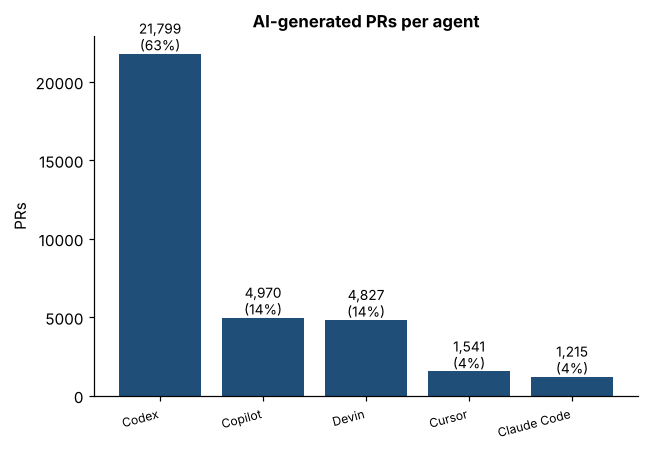

*Exact numbers – AI-generated PRs per agent*

,number,%
agent,,
Codex,21799.0,63.5
Copilot,4970.0,14.5
Devin,4827.0,14.1
Cursor,1541.0,4.5
Claude Code,1215.0,3.5
TOTAL,34352.0,100.0


In [7]:
bar(per_agent["AI_PRs"], "AI-generated PRs per agent", "1_ai_prs_per_agent.png", "PRs", pct=True)

### Chart 2 · Outcome per agent (merged / closed / open)

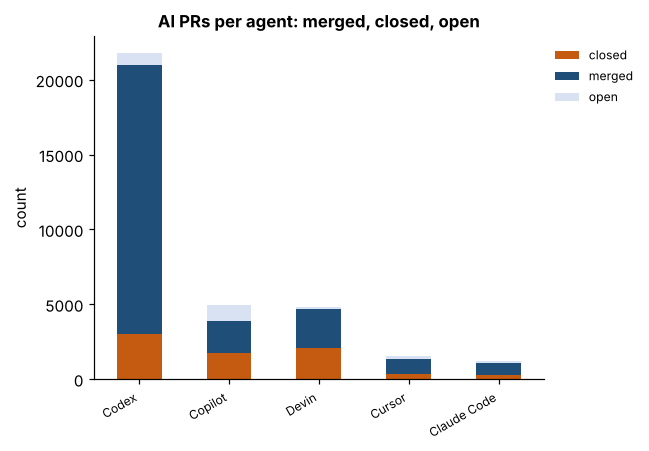

*Exact numbers – AI PRs per agent: merged, closed, open*

outcome,closed,merged,open,TOTAL
agent,,,,
Claude Code,241,846,128,1215
Cursor,342,1005,194,1541
Devin,2078,2595,154,4827
Copilot,1752,2139,1079,4970
Codex,2989,18004,806,21799
TOTAL,7402,24589,2361,34352


In [8]:
stacked(pd.crosstab(ai["agent"], ai["outcome"]).loc[per_agent.index[::-1]], "AI PRs per agent: merged, closed, open", "2_outcome_per_agent.png", colors=[ORANGE, BLUE, LIGHT])

### Chart 3 · Task type of the AI PRs (feat, fix, docs…)

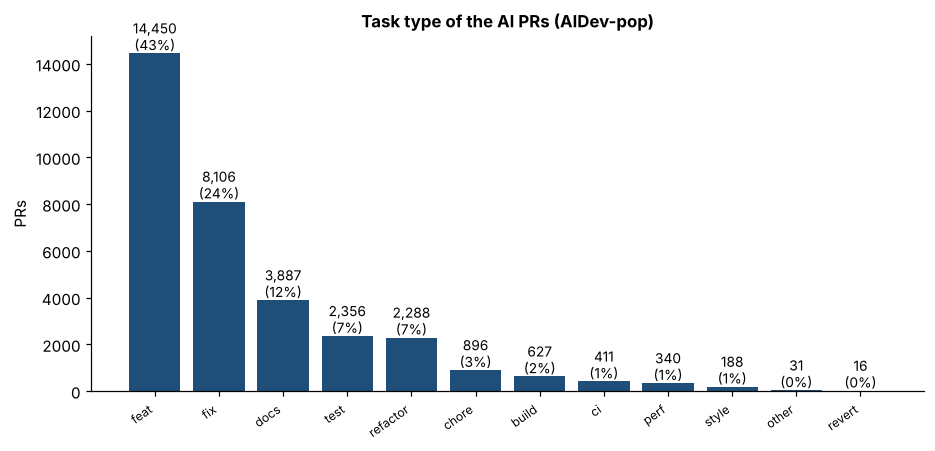

*Exact numbers – Task type of the AI PRs (AIDev-pop)*

,number,%
task_type,,
feat,14450.0,43.0
fix,8106.0,24.1
docs,3887.0,11.6
test,2356.0,7.0
refactor,2288.0,6.8
chore,896.0,2.7
build,627.0,1.9
ci,411.0,1.2
perf,340.0,1.0


In [9]:
bar(ai["task_type"].value_counts(), "Task type of the AI PRs (AIDev-pop)", "3_task_types.png", "PRs", pct=True)

### Chart 4 · AI PRs per month (how recent the data is)

/tmp/ipykernel_591/1460555123.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  m = ai.groupby([ai.created_at.dt.to_period("M").astype(str), "agent"]).size().unstack(fill_value=0)


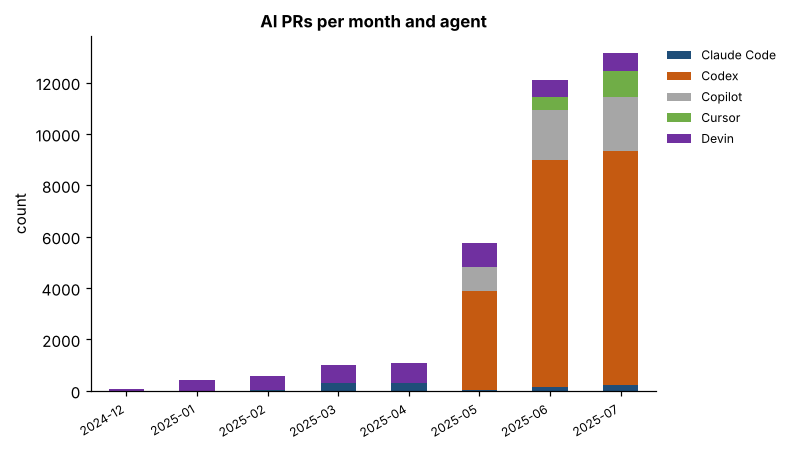

*Exact numbers – AI PRs per month and agent*

agent,Claude Code,Codex,Copilot,Cursor,Devin,TOTAL
created_at,,,,,,
2025-07,244,9089,2098,1029,679,13139
2025-06,140,8846,1952,496,673,12107
2025-05,23,3864,919,14,951,5771
2025-04,288,0,0,1,803,1092
2025-03,295,0,1,0,714,1010
2025-02,44,0,0,1,530,575
2025-01,0,0,0,0,412,412
2024-12,0,0,0,0,65,65
TOTAL,1034,21799,4970,1541,4827,34171


In [10]:
m = ai.groupby([ai.created_at.dt.to_period("M").astype(str), "agent"]).size().unstack(fill_value=0)
stacked(m.iloc[::-1], "AI PRs per month and agent", "4_prs_per_month.png", colors=[BLUE, ORANGE, GREY, "#70AD47", "#7030A0", LIGHT][: m.shape[1]])

### Extra · Python AI PRs per agent

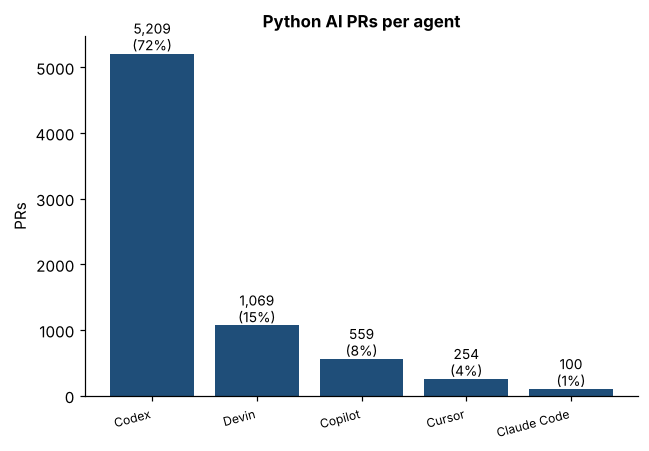

*Exact numbers – Python AI PRs per agent*

,number,%
agent,,
Codex,5209.0,72.4
Devin,1069.0,14.9
Copilot,559.0,7.8
Cursor,254.0,3.5
Claude Code,100.0,1.4
TOTAL,7191.0,100.0


In [11]:
bar(ai[ai.is_python]["agent"].value_counts(), "Python AI PRs per agent", "5_python_per_agent.png", "PRs", pct=True)

## 6. Final figure

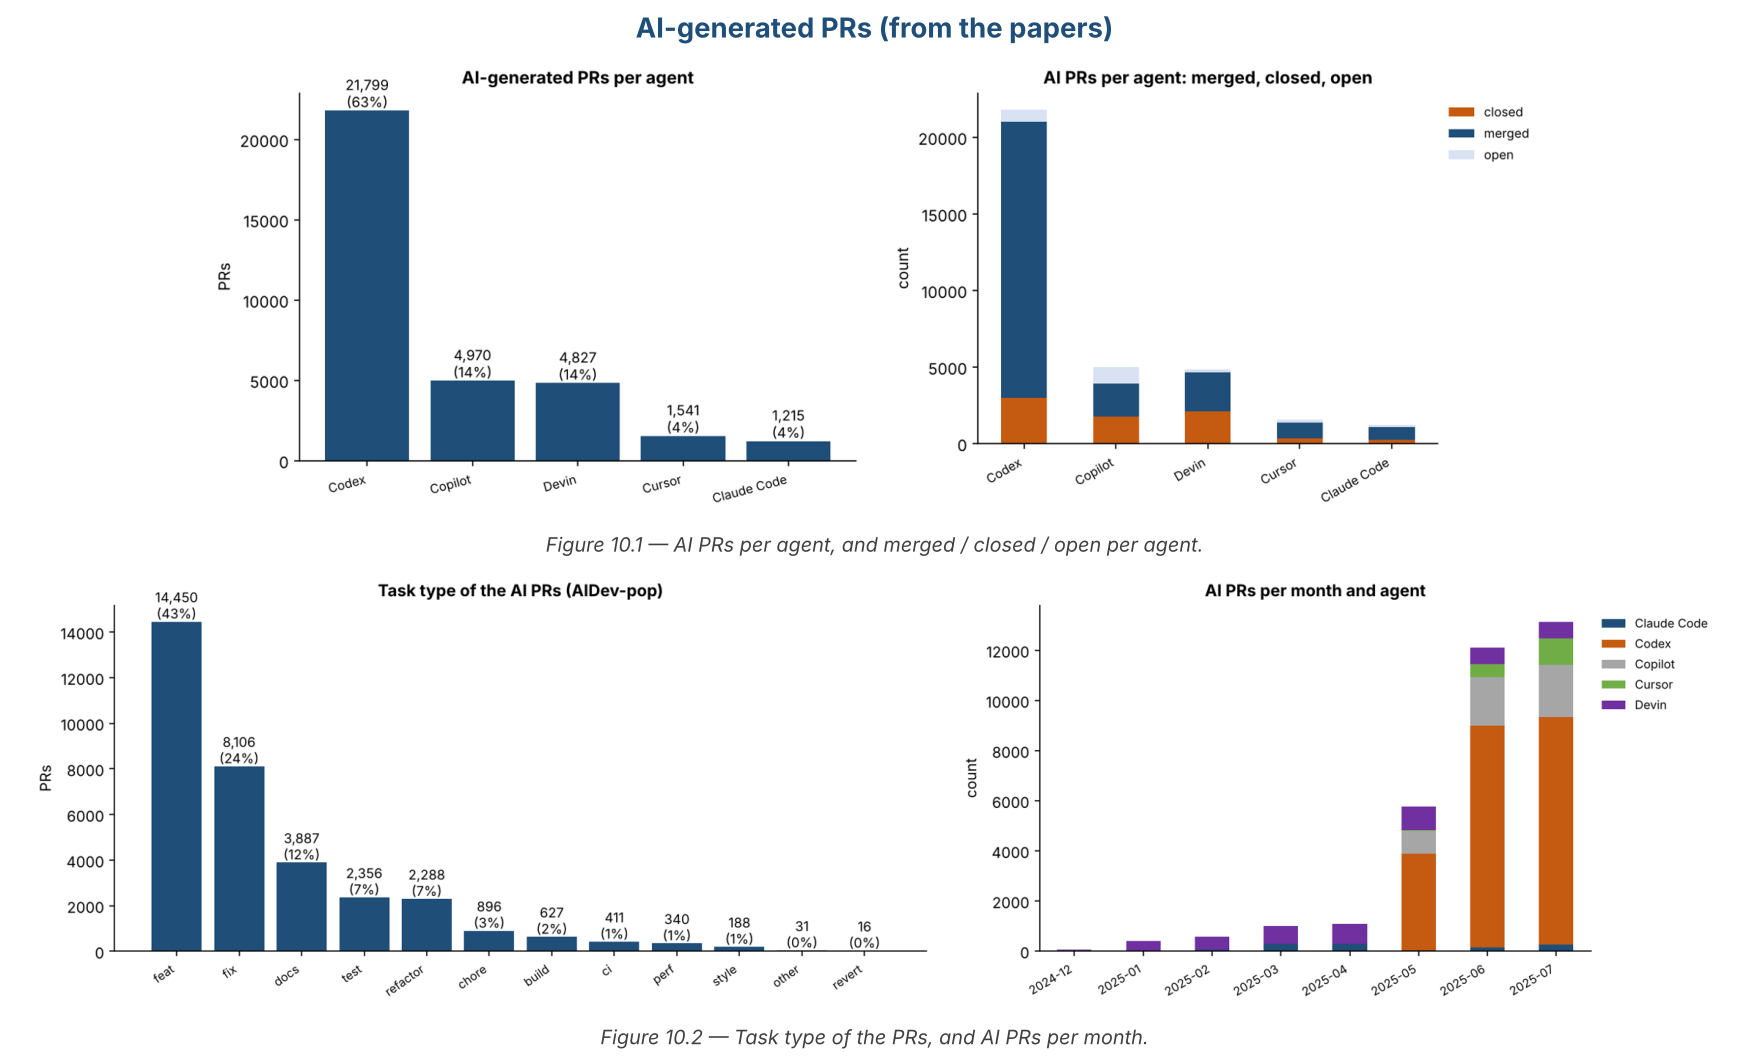

In [12]:
final_figure(10, "AI-generated PRs (from the papers)", "AI PRs per agent, and merged / closed / open per agent.", "Task type of the PRs, and AI PRs per month.")

## 7. Save the dataset

In [13]:
out = ai.copy()
for c in ["created_at", "merged_at", "closed_at"]:
    out[c] = out[c].dt.strftime("%Y-%m-%d %H:%M")
out.to_csv(os.path.join(OUT, "AI_PRS_DATASET.csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT, "AI_PRS_DATASET.xlsx")) as xw:
    out.to_excel(xw, sheet_name="AI PRs", index=False)
    per_agent.reset_index().astype(str).to_excel(xw, sheet_name="per agent", index=False)
    out[out.is_python].to_excel(xw, sheet_name="Python AI PRs", index=False)
    out[out.fixed_later].to_excel(xw, sheet_name="fixed later", index=False)
print("Saved:", OUT, "|", len(out), "AI PRs |", int(out.is_python.sum()), "Python |", int(out.fixed_later.sum()), "fixed later")

Saved: ../../data/AI_PRS_DATASET | 34352 AI PRs | 7191 Python | 948 fixed later


## 8. (Optional, on your PC) add the FULL AIDev v4 – 2.74M AI PRs up to Oct 2025
Set `RAW` to the folder with `all_pull_request.parquet` (evolution-assurance/data/raw). Saved as parquet (too big for Excel).

In [14]:
RAW = r"C:\Users\GIGABYTE\Desktop\code_theis\evolution-assurance\data\raw"   # <- change if needed
f = os.path.join(RAW, "all_pull_request.parquet")
if os.path.exists(f):
    full = pd.read_parquet(f, columns=["id", "html_url", "agent", "title", "state", "created_at", "closed_at", "merged_at", "repo_url"])
    full["agent"] = full["agent"].map(agent_of)
    full["in_papers_dataset"] = full["html_url"].isin(ai["pr_url"])
    full.to_parquet(os.path.join(OUT, "AI_PRS_AIDEV_V4_FULL.parquet"))
    display(full.groupby("agent").agg(PRs=("id", "size"), latest=("created_at", "max")).sort_values("PRs", ascending=False))
    print("Saved AI_PRS_AIDEV_V4_FULL.parquet:", len(full), "AI PRs")
else:
    print("AIDev v4 not found here – skipped (set RAW above).")

AIDev v4 not found here – skipped (set RAW above).
